In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")

test = pd.read_csv("../data/processed/test.csv", parse_dates=["StartDatetime", "EndDatetime"])
with open("../models/feature_columns.json") as file:
    FEATURES = json.load(file)["features"]

model = joblib.load("../models/best_regressor.pkl")      # the LightGBM model saved on Day 5
X_test, y_test = test[FEATURES], test["Demand"]
print(type(model).__name__)

LGBMRegressor


In [2]:
# Gain = how much each feature reduced the model's error, added up over all its splits
gain = pd.Series(model.booster_.feature_importance(importance_type="gain"), index=FEATURES)
gain_share = gain / gain.sum() * 100


def group_name(column):
    """Combine the one-hot columns so 14 location columns count as one 'Location'."""
    if column.startswith("Loc_"):
        return "Location (all types)"
    if column.startswith("TOD_"):
        return "TimeOfDay (all)"
    return column


grouped_gain = gain_share.groupby(group_name).sum().sort_values(ascending=False)
print(grouped_gain.head(12).round(1))

UserPrevAvgDemand       56.9
ChargerPrevAvgDemand    16.4
Hour                    11.5
UserPrevSessions         3.4
ChargerPrevSessions      3.2
Location (all types)     3.1
ChargerType              1.4
Month                    1.1
Day                      1.1
ChargerCompany           0.8
TimeOfDay (all)          0.5
DayOfWeek                0.5
dtype: float64


In [3]:
# Shuffle ONE feature's values at random and see how much worse the predictions get.
# A big rise in error means the model relied on that feature.
perm = permutation_importance(
    model, X_test, y_test,
    n_repeats=5, random_state=42,
    scoring="neg_mean_absolute_error", n_jobs=-1,
)
perm_importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
print("Increase in MAE (kWh) when the feature is shuffled:")
print(perm_importance.head(12).round(3))

Increase in MAE (kWh) when the feature is shuffled:
UserPrevAvgDemand       2.097
ChargerPrevAvgDemand    0.633
Hour                    0.532
UserPrevSessions        0.249
ChargerType             0.138
ChargerPrevSessions     0.064
Loc_market              0.034
Loc_company             0.021
Loc_resort              0.017
Loc_public_area         0.017
Loc_apartment           0.017
TOD_Morning             0.013
dtype: float64


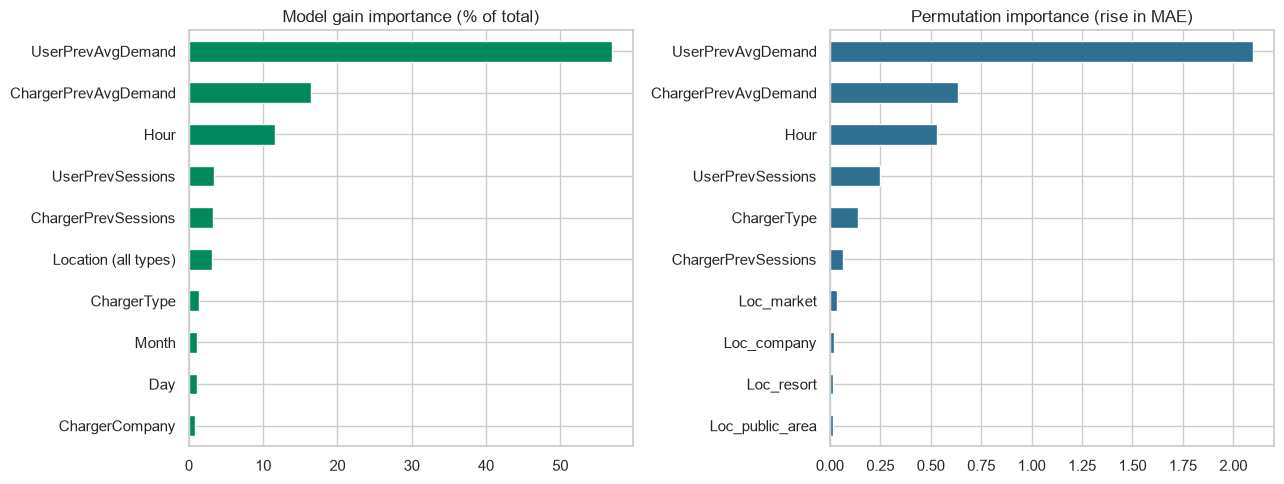

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

grouped_gain.head(10).sort_values().plot(kind="barh", ax=axes[0], color="#00895C")
axes[0].set_title("Model gain importance (% of total)")

perm_importance.head(10).sort_values().plot(kind="barh", ax=axes[1], color="#2F6F8F")
axes[1].set_title("Permutation importance (rise in MAE)")

plt.tight_layout()
plt.savefig("../docs/figures/12_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
has_history = test[test["HasUserHistory"] == 1].copy()
has_history["UserHistoryBand"] = pd.qcut(has_history["UserPrevAvgDemand"], 5)

print(has_history.groupby("UserHistoryBand", observed=True)["Demand"].agg(["size", "mean"]).round(1))

                  size  mean
UserHistoryBand             
(0.019, 8.921]    1747   7.6
(8.921, 13.717]   1746  12.1
(13.717, 18.657]  1747  16.4
(18.657, 26.574]  1746  21.7
(26.574, 85.7]    1747  32.5


In [6]:
pd.DataFrame({"gain_share_pct": gain_share, "permutation_mae_rise": perm_importance}).round(4) \
    .sort_values("permutation_mae_rise", ascending=False) \
    .to_csv("../models/feature_importance.csv")